# Stock 9: predicting the future, three months ahead

Stock 9 has a `day` column, and the test row is **after** the last training day. So this round isn't really "predict a row like the others": it's a **forecast**. Time hides three patterns here, and a model that misses any of them is off by pounds.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Look at the data over time and find the patterns |
| 3 | Compare many models fairly, with a test that copies forecasting |
| 4 | Does mixing models help? |
| 5 | Predict stock 9 |
| 6 | Measure how sure we are |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column of the data: `day` and `x1` to `x7`. |
| **Trend** | The steady rise of the price over the days. |
| **Jump** | A sudden one-off step in the price level. |
| **Weekly cycle** | A pattern that repeats every 7 days. |
| **Random CV** | Cross-validation with rows picked at random: the model gets to see days on both sides of every test row. |
| **Walk-forward test** | Train only on days **before** a cutoff, then test 61–120 days **after** it, like our real problem (the test row is 91 days after the last training day). |

Run the cells from top to bottom (or **Restart**, then **Run All**). Part 3 takes about 15 minutes.

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.optimize import nnls

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

pd.set_option("display.max_colwidth", None)    # show long text in tables in full, without "..."
print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_9_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_9_test.csv")     # the one row we must price


x_clues = [c for c in train.columns if c.startswith("x")]   # x1 ... x7
clue_columns = ["day"] + x_clues

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
print("Clues:        ", len(clue_columns), "(day and x1–x7)")
train.head()

Training data: 60000 rows
Test data:     1 row
Clues:         8 (day and x1–x7)


,uid,day,x1,x2,x3,x4,x5,x6,x7,price
0,022bbae6d5,132,0.0408,-0.4541,0.1393,0.6669,-0.5330,0.6785,-0.4475,105.43
1,0c8aaab18e,325,-1.6513,0.4048,-0.8100,0.6559,0.9097,0.0906,0.8085,114.94
2,c0a4772c30,80,-0.4408,-1.5587,-1.1059,0.5821,-1.0416,-0.7823,1.9740,98.40
3,efe061ec72,422,2.2873,-0.8457,1.2348,0.6718,-1.0674,0.3398,-2.0164,125.55
4,fefdae31bd,280,1.8528,0.9057,0.4961,0.8683,1.7380,-0.4317,0.9303,119.94


### Step 1.3: Quick health check

In [3]:
print("Empty cells in train:", train.isna().sum().sum())
print("Empty cells in test: ", test[clue_columns].isna().sum().sum())
print("Repeated rows in train:", train[clue_columns].duplicated().sum())
rows_per_day = train.groupby("day").size()
print(f"\nDays in training: {train['day'].min()} to {train['day'].max()} ({train['day'].nunique()} different days, "
      f"{rows_per_day.min()}–{rows_per_day.max()} rows per day)")
print(f"Test row's day: {test['day'].iloc[0]}  →  {test['day'].iloc[0] - train['day'].max()} days after the last training day")
print()
print(train[clue_columns + ["price"]].describe().round(2).to_string())

Empty cells in train: 0
Empty cells in test:  0
Repeated rows in train: 0

Days in training: 0 to 729 (730 different days, 60–111 rows per day)
Test row's day: 820  →  91 days after the last training day

           day        x1        x2        x3        x4        x5        x6        x7     price
count  60000.0  60000.00  60000.00  60000.00  60000.00  60000.00  60000.00  60000.00  60000.00
mean     364.4      0.00      0.20     -0.00      0.50      0.00      0.00      0.00    120.14
std      211.1      1.00      1.00      1.00      0.29      1.00      0.99      1.00     14.51
min        0.0     -4.29     -4.02     -4.32      0.00     -4.35     -4.43     -4.36     78.71
25%      182.0     -0.68     -0.47     -0.67      0.25     -0.67     -0.67     -0.68    108.82
50%      364.0      0.01      0.21     -0.00      0.50      0.00      0.01      0.00    118.72
75%      548.0      0.68      0.88      0.68      0.75      0.68      0.67      0.68    130.28
max      729.0      4.39      4.26 

* Clean: no empty cells, no repeats.
* Training covers **days 0 to 729** (two years, about 80 rows per day). The test row is **day 820**, **91 days after** the last training day.
* Prices average about **£120** (sd £14.5).

> **✅ Checkpoint.** 60,000 clean rows over 730 days. The test row is three months **in the future**.

---
# Part 2: Look at the data over time

### Step 2.1: Is the test row "normal"?

In [4]:
test_row = test[clue_columns].iloc[0]
check = pd.DataFrame({
    "test row": test_row,
    "smallest in training": train[clue_columns].min(),
    "largest in training": train[clue_columns].max(),
    "std steps from average": ((test_row - train[clue_columns].mean()) / train[clue_columns].std()).round(2),
})
check

,test row,smallest in training,largest in training,std steps from average
day,820.0000,0.0000,729.0000,2.16
x1,0.5506,-4.2891,4.3910,0.55
x2,1.8048,-4.0202,4.2601,1.60
x3,-0.3977,-4.3198,4.1435,-0.40
x4,0.3267,0.0000,1.0000,-0.60
x5,0.1226,-4.3537,4.4136,0.12
x6,-0.6602,-4.4296,4.1181,-0.66
x7,0.8972,-4.3595,4.2493,0.89


`x1`–`x7` are all ordinary values. **`day` is not**: 820 is beyond the largest training day (729). Every model has to **extend** whatever it learned about time into days it has never seen.

### Step 2.2: The price over time

We average the price over each day and plot it. (Each day has about 80 rows, so the daily average is much smoother than single rows.)

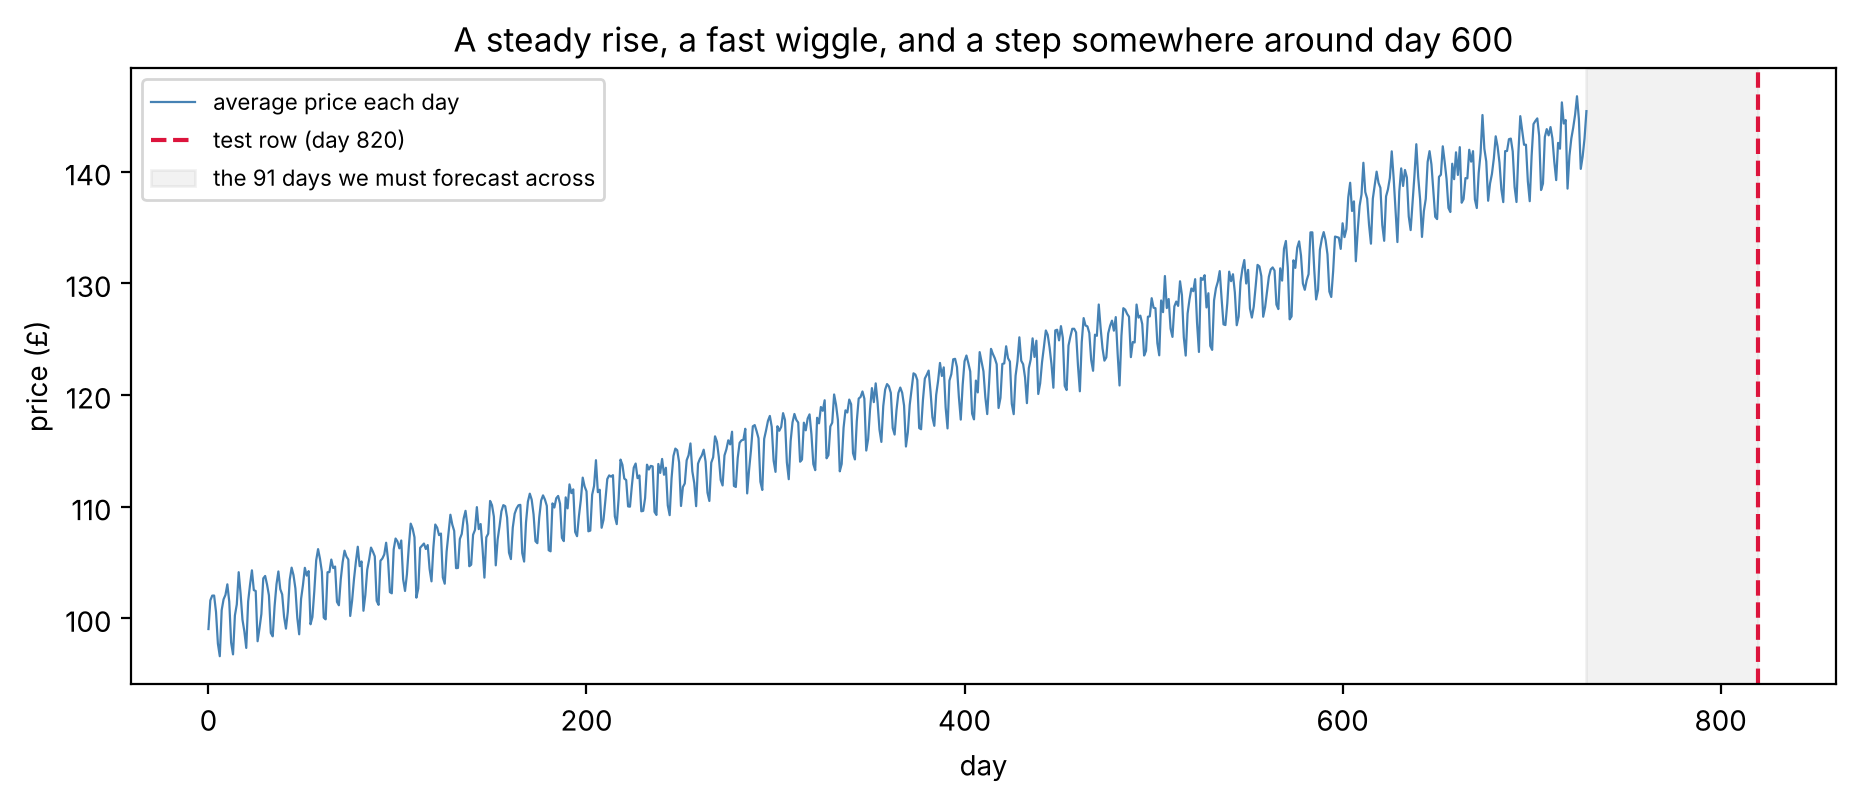

In [5]:
daily_price = train.groupby("day")["price"].mean()

plt.figure(figsize=(11, 4))
plt.plot(daily_price.index, daily_price.values, color="steelblue", linewidth=0.8, label="average price each day")
plt.axvline(test_row["day"], color="crimson", linestyle="--", linewidth=1.5, label="test row (day 820)")
plt.axvspan(train["day"].max(), test_row["day"], color="grey", alpha=0.1, label="the 91 days we must forecast across")
plt.xlabel("day"); plt.ylabel("price (£)")
plt.title("A steady rise, a fast wiggle, and a step somewhere around day 600")
plt.legend(loc="upper left", fontsize=8)
plt.show()

Three things are visible:

1. A **steady rise** (the trend) of about £1.50 a month.
2. A fast **wiggle** on top of it.
3. A **step up** somewhere around day 600.

Let's take them one at a time.

### Step 2.3: The fast wiggle is a weekly cycle

We remove the steady trend with a simple straight line, then average what's left by **`day % 7`** (the remainder when dividing the day by 7, i.e. "which day of the week").

Day-to-day pattern repeats every 7 days? Correlation with 7 days earlier: 0.88,  with 1 day earlier: 0.58


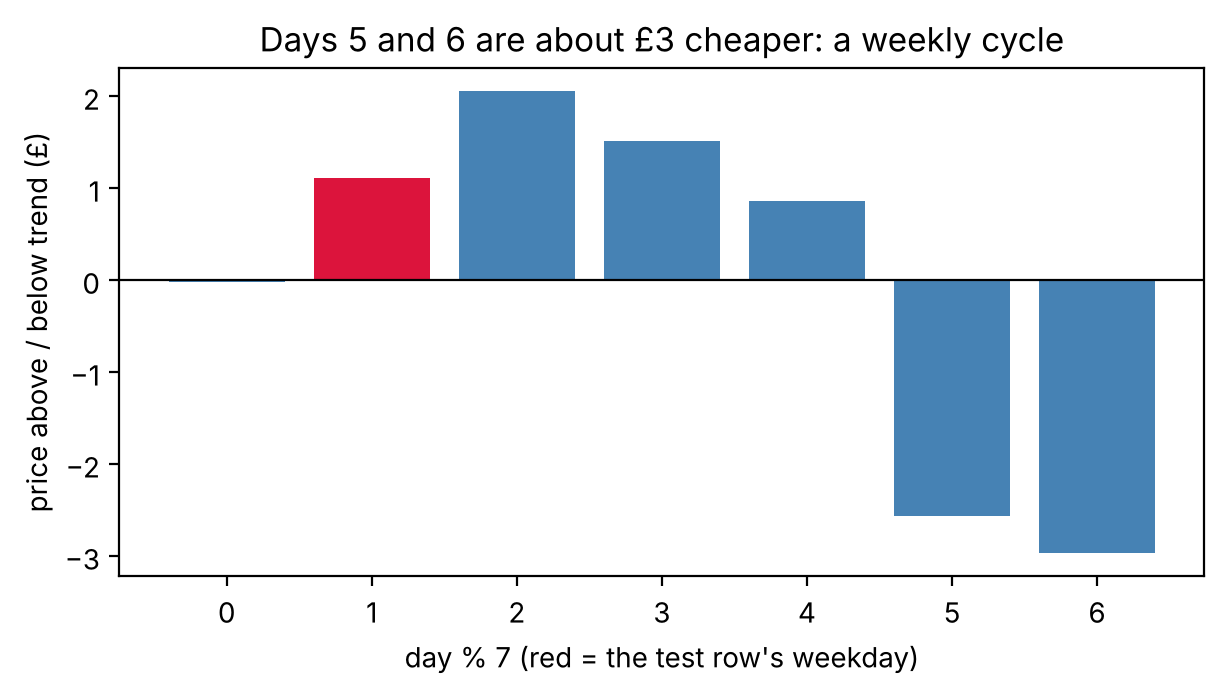

Test row: day 820 % 7 = 1


In [6]:
trend = np.polyfit(daily_price.index, daily_price.values, 1)                     # a simple straight line through the days
left_over = daily_price - np.polyval(trend, daily_price.index)
weekday = pd.Series(daily_price.index % 7, index=daily_price.index)

print(f"Day-to-day pattern repeats every 7 days? Correlation with 7 days earlier: {left_over.autocorr(7):.2f},  with 1 day earlier: {left_over.autocorr(1):.2f}")
by_weekday = left_over.groupby(weekday).mean()

plt.figure(figsize=(7, 3.3))
colours = ["crimson" if d == test_row["day"] % 7 else "steelblue" for d in by_weekday.index]
plt.bar(by_weekday.index, by_weekday.values, color=colours)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("day % 7 (red = the test row's weekday)"); plt.ylabel("price above / below trend (£)")
plt.title("Days 5 and 6 are about £3 cheaper: a weekly cycle")
plt.show()
print(f"Test row: day {int(test_row['day'])} % 7 = {int(test_row['day'] % 7)}")

* The wiggle repeats **every 7 days** (correlation **0.95** with a week earlier).
* Weekdays 5 and 6 sit about **£2.5–£3 below** the trend, weekdays 1–3 about £1–£2 above. It looks like a weekend.
* The test row is weekday **1**, one of the more expensive days. A model that ignores the cycle loses about £1–£2 on this row.

### Step 2.4: Do the clues' effects change over time?

We split the two years into 8 quarters (91 days each) and fit a separate straight line in each quarter. If a clue's weight changes from quarter to quarter, its effect is **changing over time**.

In [7]:
quarter = train["day"] // 91
rows = []
for q, part in train[quarter < 8].groupby(quarter[quarter < 8]):
    m = LinearRegression().fit(part[clue_columns], part["price"])
    rows.append({"quarter": int(q), "days": f"{q * 91}–{q * 91 + 90}", **dict(zip(clue_columns, m.coef_.round(2)))})
weights_by_quarter = pd.DataFrame(rows)
weights_by_quarter

,quarter,days,day,x1,x2,x3,x4,x5,x6,x7
0,0,0–90,0.05,3.00,2.32,2.04,0.18,0.01,-0.06,0.01
1,1,91–181,0.05,3.01,3.09,1.87,0.10,0.05,0.06,0.09
2,2,182–272,0.05,3.01,3.85,1.96,-0.02,0.03,0.06,-0.03
3,3,273–363,0.05,3.02,4.67,1.99,0.00,0.01,-0.06,0.03
4,4,364–454,0.05,3.05,5.35,2.05,0.11,0.03,0.04,0.01
5,5,455–545,0.05,2.97,6.08,1.97,-0.28,0.04,-0.02,0.07
6,6,546–636,0.11,2.98,6.85,2.01,-0.31,-0.02,0.15,-0.00
7,7,637–727,0.05,3.04,7.63,1.89,0.03,0.01,0.03,-0.00


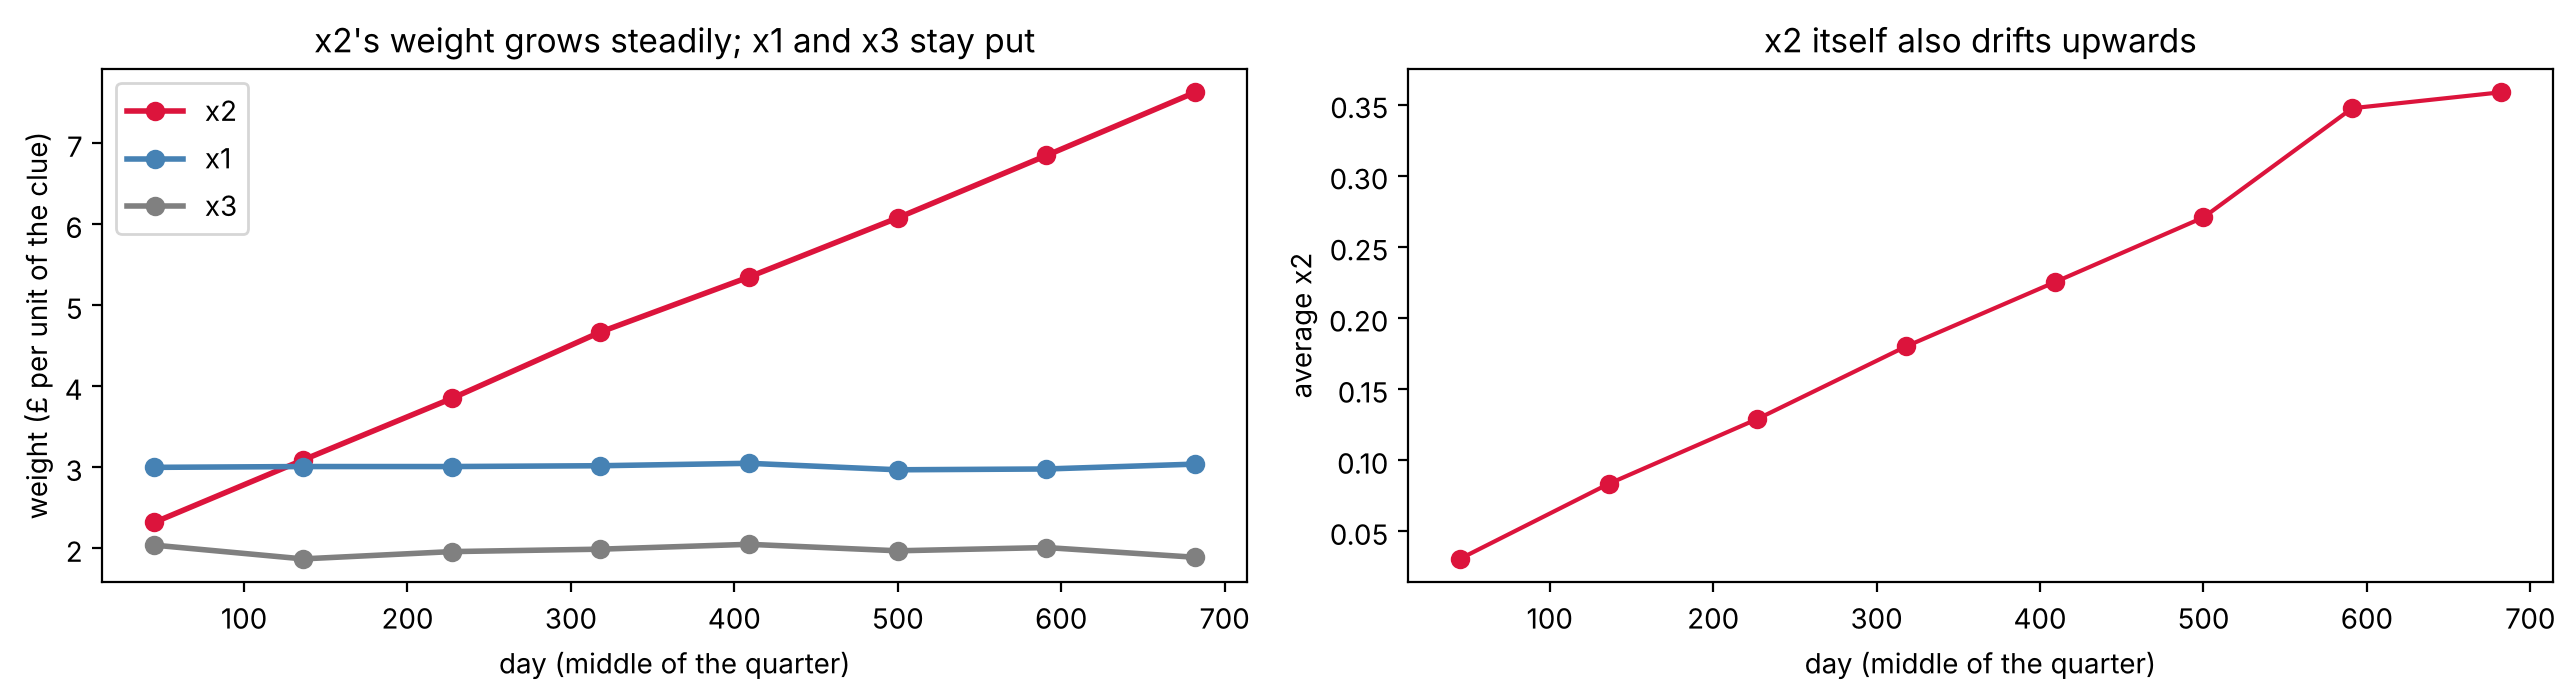

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.6))
centres = weights_by_quarter["quarter"] * 91 + 45
for clue, colour in [("x2", "crimson"), ("x1", "steelblue"), ("x3", "grey")]:
    left.plot(centres, weights_by_quarter[clue], marker="o", linewidth=2, color=colour, label=clue)
left.set_xlabel("day (middle of the quarter)"); left.set_ylabel("weight (£ per unit of the clue)")
left.set_title("x2's weight grows steadily; x1 and x3 stay put"); left.legend()

right.plot(centres, train[quarter < 8].groupby(quarter[quarter < 8])["x2"].mean(), marker="o", color="crimson")
right.set_xlabel("day (middle of the quarter)"); right.set_ylabel("average x2")
right.set_title("x2 itself also drifts upwards")
plt.tight_layout()
plt.show()

**This is the second time pattern.**

* `x1` (≈ £3 per unit) and `x3` (≈ £2) have the **same** weight in every quarter. `x4`–`x7` stay near 0.
* **`x2`'s weight grows every quarter**, from about £2.3 to about £7.6, roughly **+£0.76 per quarter**, in a straight line.
* If it keeps growing, by day 820 it will be about **£8.8** per unit. A model that uses one fixed weight for `x2` (the two-year average, about £5) gets this badly wrong for our test row, whose `x2` is **1.80**: about **£7** too low.
* The fix: give the model `x2 × day`, so the weight of `x2` can grow with time.

### Step 2.5: Where exactly is the step?

We try every possible step day between 560 and 650. For each, we fit trend + step + all the clues, and keep the day that fits best.

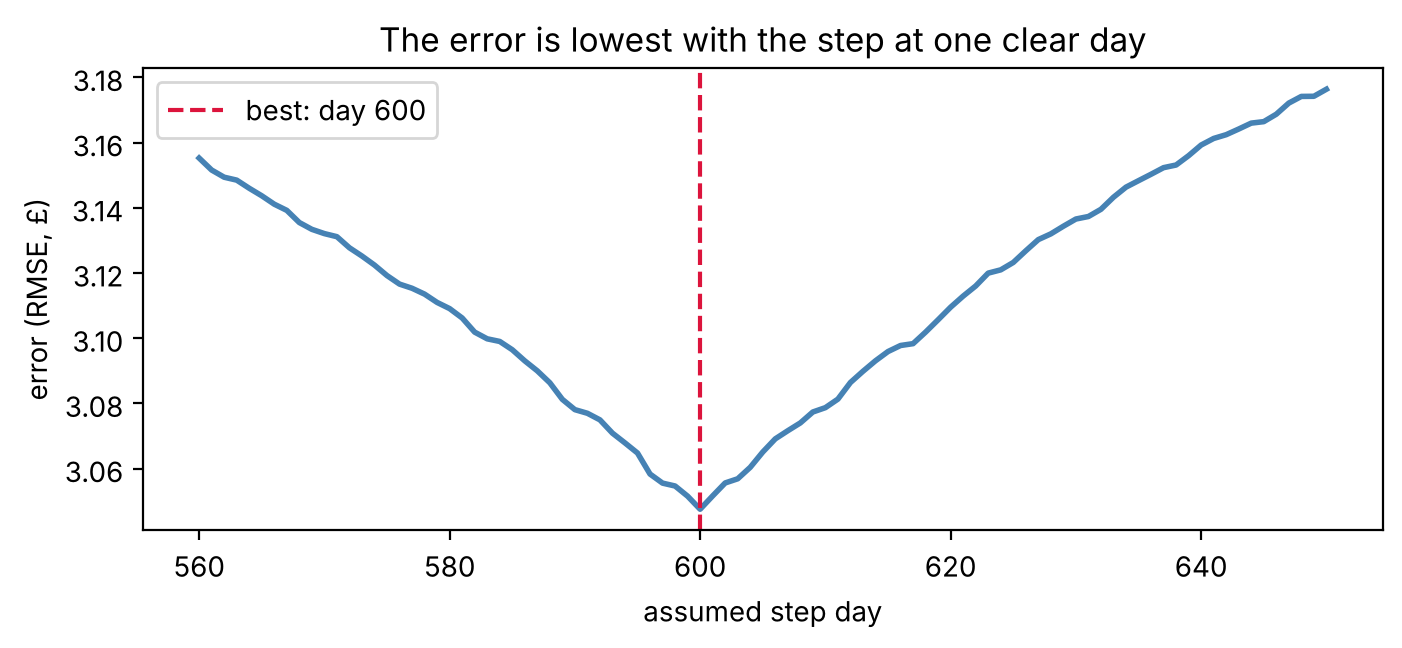

Step day: 600,  step size: £3.99


In [9]:
def with_step(d, step_day):
    return np.column_stack([d["day"], d["day"] >= step_day, d[x_clues], d["x2"] * d["day"], d["day"] % 7 == 5, d["day"] % 7 == 6])

scan = []
for step_day in range(560, 651):
    m = LinearRegression().fit(with_step(train, step_day), train["price"])
    scan.append({"step day": step_day, "error (RMSE, £)": np.sqrt(np.mean((train["price"] - m.predict(with_step(train, step_day))) ** 2)),
                 "step size (£)": m.coef_[1]})
scan = pd.DataFrame(scan)
JUMP_DAY = int(scan.loc[scan["error (RMSE, £)"].idxmin(), "step day"])

plt.figure(figsize=(8, 3))
plt.plot(scan["step day"], scan["error (RMSE, £)"], color="steelblue", linewidth=2)
plt.axvline(JUMP_DAY, color="crimson", linestyle="--", label=f"best: day {JUMP_DAY}")
plt.xlabel("assumed step day"); plt.ylabel("error (RMSE, £)"); plt.legend()
plt.title("The error is lowest with the step at one clear day")
plt.show()
print(f"Step day: {JUMP_DAY},  step size: £{scan.set_index('step day').loc[JUMP_DAY, 'step size (£)']:.2f}")

**How to read this**

* There's one clear best day, **600**. Overnight, the price level steps up by about **£4.0**, and the trend carries on at the same pace on both sides.
* A step like this can't be predicted from the data before it. That matters for us: the test row is 91 days past our last day, and nothing guarantees there won't be another one.

> **✅ Checkpoint.** Three time patterns: (1) a steady **trend** plus a one-off **step** of about £4 at day 600; (2) a **weekly cycle** worth about ±£3; (3) the weight of **`x2` grows over time**. The test row is 91 days into the future, on an expensive weekday, with a fairly large `x2`. All three matter.

---
# Part 3: Compare models fairly

### Step 3.1: Two tests

1. **Random 5-fold CV** (what most teams will do). Rows are picked at random, so every test row has training rows from **the same day** and from days on **both sides**. It never asks a model to forecast.
2. **Walk-forward test.** Pick a cutoff day. Train only on days **before** it, and test on days **61 to 120 after** it (the test row is 91 days after our last day). We do this for 5 cutoffs: 400, 460, 520, 580 and 609.

**We choose each model's settings by the walk-forward test.**

In [10]:
X = train[clue_columns]          # the clues
y = train["price"]               # the answers
X_test = test[clue_columns]      # the test row's clues

random_cv = KFold(n_splits=5, shuffle=True, random_state=0)

cutoffs = [400, 460, 520, 580, 609]
walk_forward = []
for c in cutoffs:
    learn = np.where(X["day"] < c)[0]                                         # only the past
    check = np.where((X["day"] >= c + 61) & (X["day"] < c + 121))[0]           # 61–120 days later
    walk_forward.append((learn, check))
    print(f"cutoff {c}: learn on days 0–{c - 1} ({len(learn)} rows), test on days {c + 61}–{c + 120} ({len(check)} rows)")

cutoff 400: learn on days 0–399 (32932 rows), test on days 461–520 (4864 rows)
cutoff 460: learn on days 0–459 (37853 rows), test on days 521–580 (4870 rows)
cutoff 520: learn on days 0–519 (42718 rows), test on days 581–640 (5007 rows)
cutoff 580: learn on days 0–579 (47583 rows), test on days 641–700 (4892 rows)
cutoff 609: learn on days 0–608 (50023 rows), test on days 670–729 (4984 rows)


Note that the cutoffs at 520 and 580 test on days **after** the step at day 600, which their training data has never seen. That's deliberate: it shows what an unexpected change does to a forecast.

### Step 3.2: The models

All models get the raw clues: `day` and `x1`–`x7`.

**Group A, GridSearchCV:** linear regression, Ridge, Lasso, ElasticNet, Huber, random forest, SVR, MLP.
(SVR's training time grows with the **square** of the rows, so it learns from a random 15,000 of them.)

**Group B, RandomizedSearchCV (8 random combinations each):** XGBoost, LightGBM, CatBoost.

In [11]:
grid_models = {
    "Linear regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-2, 3, 6)}),
    "Lasso": (Lasso(max_iter=20000), {"model__alpha": np.logspace(-3, 0, 6)}),
    "ElasticNet": (ElasticNet(max_iter=20000), {"model__alpha": np.logspace(-3, 0, 4),
                                                "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "Huber": (HuberRegressor(max_iter=1000), {"model__epsilon": [1.35, 2.0, 3.0]}),
    "Random forest": (RandomForestRegressor(n_estimators=150, random_state=0, n_jobs=1),
                      {"model__min_samples_leaf": [5, 20, 50]}),
    "SVR": (BaggingRegressor(SVR(epsilon=0.5, cache_size=1000), n_estimators=1, max_samples=15000, random_state=0),
            {"model__estimator__C": [10, 100]}),
    "MLP": (MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=0),
            {"model__alpha": [1e-4, 1e-2]}),
}
random_models = {
    "XGBoost": (XGBRegressor(random_state=0, n_jobs=1),
                {"model__n_estimators": [300, 600],
                 "model__learning_rate": [0.03, 0.1],
                 "model__max_depth": [3, 4, 6],
                 "model__min_child_weight": [1, 5, 20],
                 "model__subsample": [0.7, 1.0],
                 "model__reg_lambda": [1, 10]}),
    "LightGBM": (LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1),
                 {"model__n_estimators": [300, 600],
                  "model__learning_rate": [0.03, 0.1],
                  "model__num_leaves": [7, 15, 31],
                  "model__min_child_samples": [20, 100],
                  "model__subsample": [0.7, 1.0],
                  "model__reg_lambda": [0, 10]}),
    "CatBoost": (CatBoostRegressor(random_seed=0, verbose=0, thread_count=1, allow_writing_files=False),
                 {"model__iterations": [300, 600],
                  "model__learning_rate": [0.05, 0.1],
                  "model__depth": [4, 6],
                  "model__l2_leaf_reg": [1, 10]}),
}
N_ITER = 8
print("Group A:", list(grid_models.keys()))
print("Group B:", list(random_models.keys()))

Group A: ['Linear regression', 'Ridge', 'Lasso', 'ElasticNet', 'Huber', 'Random forest', 'SVR', 'MLP']
Group B: ['XGBoost', 'LightGBM', 'CatBoost']


### Step 3.3: Run the contest

About 10–15 minutes.

In [12]:
results = []
searches = {}

def record(name, search):
    # save one finished search: walk-forward score, random-CV score and its price for the test row
    searches[name] = search
    random_score = -cross_val_score(search.best_estimator_, X, y, cv=random_cv,
                                    scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    results.append({
        "model": name,
        "random CV RMSE (£)": round(random_score, 2),
        "walk-forward RMSE (£)": round(-search.best_score_, 2),
        "test prediction (£)": round(float(np.ravel(search.predict(X_test))[0]), 2),
        "best settings": search.best_params_,
    })
    print(f"{name} done")

for name, (model, settings) in grid_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = GridSearchCV(pipe, settings, cv=walk_forward, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (model, settings) in random_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = RandomizedSearchCV(pipe, settings, n_iter=N_ITER, cv=walk_forward, random_state=0,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

pd.DataFrame(results).sort_values("walk-forward RMSE (£)").reset_index(drop=True)

Linear regression done


Ridge done


Lasso done


ElasticNet done


Huber done


Random forest done


... (2 outputs left out)

XGBoost done


LightGBM done


CatBoost done


,model,random CV RMSE (£),walk-forward RMSE (£),test prediction (£),best settings
0,MLP,3.60,4.32,164.85,{'model__alpha': 0.0001}
1,Huber,4.13,5.49,154.56,{'model__epsilon': 1.35}
2,Linear regression,4.13,5.50,154.74,{}
3,Ridge,4.13,5.50,154.74,{'model__alpha': 0.01}
4,ElasticNet,4.13,5.50,154.73,"{'model__alpha': 0.001, 'model__l1_ratio': 0.8}"
5,Lasso,4.13,5.50,154.73,{'model__alpha': 0.001}
6,SVR,3.97,5.83,163.19,{'model__estimator__C': 100}
7,CatBoost,3.45,7.40,155.45,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 1, 'model__iterations': 300, 'model__depth': 6}"
8,XGBoost,3.50,7.77,155.12,"{'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__n_estimators': 600, 'model__min_child_weight': 20, 'model__max_depth': 3, 'model__learning_rate': 0.03}"
9,LightGBM,3.45,7.96,154.72,"{'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__num_leaves': 15, 'model__n_estimators': 300, 'model__min_child_samples': 100, 'model__learning_rate': 0.1}"


**What this shows**

* On **random CV** the tree models look good: CatBoost, LightGBM, XGBoost and random forest score **£3.45–£3.64**, better than linear regression (£4.13).
* On the **walk-forward test** they're the **worst**: **£7.4–£8.1**. A tree can't extend the trend past the last day it has seen, so 61–120 days later it's always too low. For the test row they say **£154.7–£155.5**.
* Plain linear regression does extend the trend (£5.50 walk-forward), but it uses one fixed weight for `x2` and ignores the weekly cycle and the step: **£154.7**.
* The **MLP** is the best standard model (£4.32 walk-forward, **£164.85**): its straight-line pieces let it extend the trend, and it partly picks up the growing `x2` weight. SVR: £5.83 and **£163.19**.

### Step 3.4: Use what we learned in Part 2

We build the time patterns into a plain linear regression, the **time model**:

| Ingredient | Why |
|---|---|
| `day` | the steady trend |
| `day ≥ 600` (0 or 1) | the step |
| weekday dummies: `day % 7 == 1`, …, `== 6` | the weekly cycle (each weekday gets its own level) |
| `x1`–`x7` | the clues |
| `x2 × day` | lets the weight of `x2` grow over time |

To check that each ingredient earns its place, we also try the time model **without** each one.

In [13]:
def time_clues(d, use_step=True, use_weekday=True, use_x2_growth=True):
    parts = [d["day"]]
    if use_step:
        parts.append((d["day"] >= JUMP_DAY).astype(float))
    if use_weekday:
        parts += [(d["day"] % 7 == k).astype(float) for k in range(1, 7)]
    parts += [d[c] for c in x_clues]
    if use_x2_growth:
        parts.append(d["x2"] * d["day"])
    return np.column_stack(parts)

def time_model(**options):
    return Pipeline([("clues", FunctionTransformer(time_clues, kw_args=options)), ("model", LinearRegression())])

extra_models = {
    "Time model": time_model(),
    "Time model without x2 × day": time_model(use_x2_growth=False),
    "Time model without weekday": time_model(use_weekday=False),
    "Time model without the step": time_model(use_step=False),
}
for name, pipe in extra_models.items():
    search = GridSearchCV(pipe, {}, cv=walk_forward, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

results_table = pd.DataFrame(results).sort_values("walk-forward RMSE (£)").reset_index(drop=True)
results_table

Time model done


Time model without x2 × day done


Time model without weekday done


Time model without the step done


,model,random CV RMSE (£),walk-forward RMSE (£),test prediction (£),best settings
0,Time model,2.99,3.67,162.87,{}
1,Time model without the step,3.20,4.03,162.05,{}
2,Time model without weekday,3.51,4.16,161.70,{}
3,MLP,3.60,4.32,164.85,{'model__alpha': 0.0001}
4,Time model without x2 × day,3.46,4.81,157.12,{}
5,Huber,4.13,5.49,154.56,{'model__epsilon': 1.35}
6,Linear regression,4.13,5.50,154.74,{}
7,Ridge,4.13,5.50,154.74,{'model__alpha': 0.01}
8,Lasso,4.13,5.50,154.73,{'model__alpha': 0.001}
9,ElasticNet,4.13,5.50,154.73,"{'model__alpha': 0.001, 'model__l1_ratio': 0.8}"


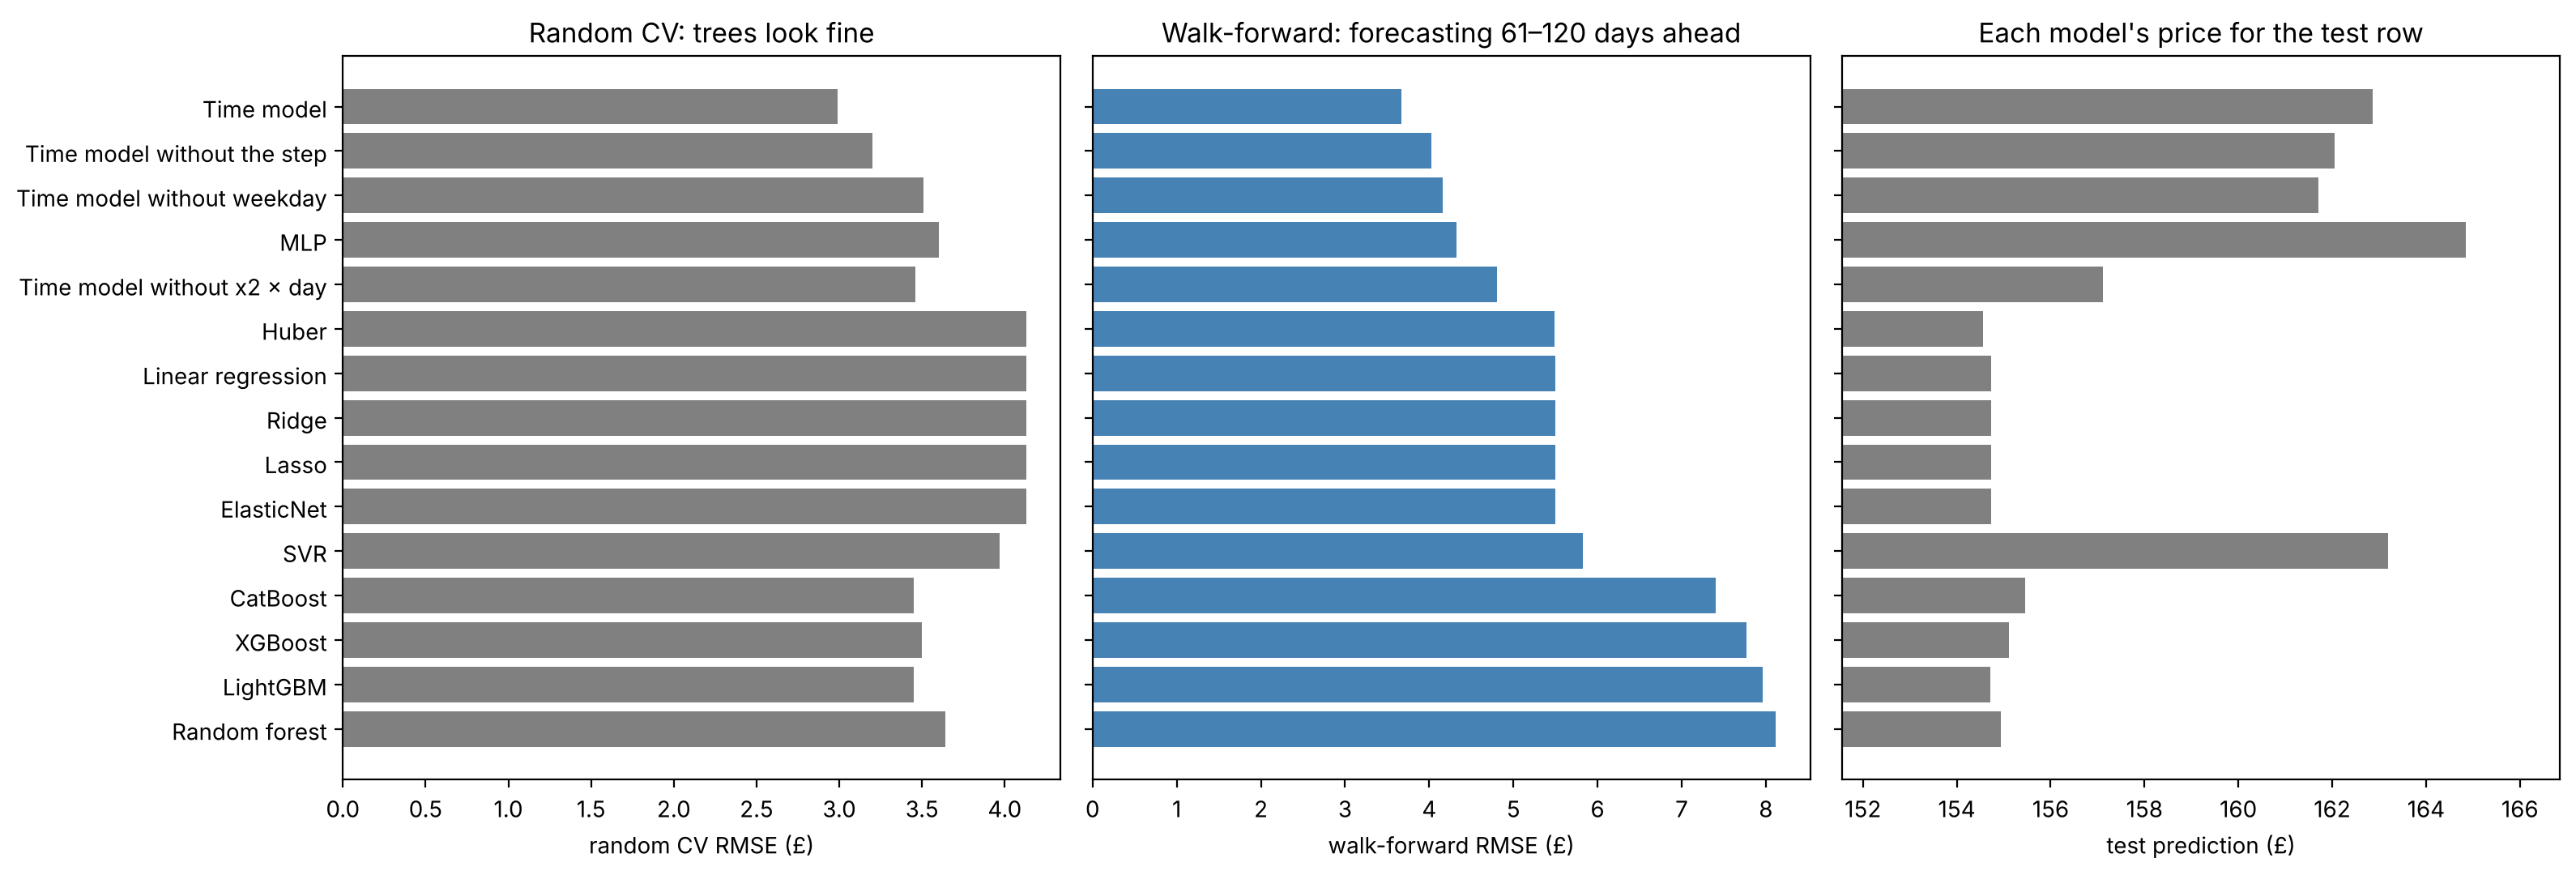

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
for ax, column, colour, title in [
        (axes[0], "random CV RMSE (£)", "grey", "Random CV: trees look fine"),
        (axes[1], "walk-forward RMSE (£)", "steelblue", "Walk-forward: forecasting 61–120 days ahead"),
        (axes[2], "test prediction (£)", "grey", "Each model's price for the test row")]:
    ax.barh(results_table["model"], results_table[column], color=colour)
    ax.set_xlabel(column); ax.set_title(title)
axes[2].set_xlim(results_table["test prediction (£)"].min() - 3, results_table["test prediction (£)"].max() + 2)
axes[0].invert_yaxis()                                        # best walk-forward model at the top
plt.tight_layout()
plt.show()

**What this shows**

* The **time model** wins both tests: **£2.99** on random CV (that's the noise itself) and **£3.67** on walk-forward.
* Every ingredient earns its place. Walk-forward rises to £4.03 without the step, £4.16 without the weekly cycle, and £4.81 without `x2 × day`.
* For **this test row**, `x2 × day` matters most: without it the price drops from **£162.87 to £157.12**, because the test row's `x2` (1.80) is large and its weight keeps growing.
* The trees, plain linear regression and the "no `x2 × day`" model (what most teams will end up with) all price the test row at **£154.6–£157.1**, about **£6–£8 below** us.

In [15]:
best = searches["Time model"].best_estimator_.named_steps["model"]
labels = ["day", "step"] + [f"weekday {k}" for k in range(1, 7)] + x_clues + ["x2 × day"]
weights_table = pd.DataFrame({"ingredient": labels, "weight": best.coef_.round(4)})
print(f"start (intercept): {best.intercept_:.2f}")
print(f"weight of x2 on day 0: {weights_table.set_index('ingredient').loc['x2', 'weight']:.2f},  "
      f"on day 820: {weights_table.set_index('ingredient').loc['x2', 'weight'] + 820 * weights_table.set_index('ingredient').loc['x2 × day', 'weight']:.2f}")
weights_table.T

start (intercept): 99.96
weight of x2 on day 0: 1.98,  on day 820: 8.79


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
ingredient,day,step,weekday 1,weekday 2,weekday 3,weekday 4,weekday 5,weekday 6,x1,x2,x3,x4,x5,x6,x7,x2 × day
weight,0.0501,3.9899,1.2106,2.0307,1.4745,0.83,-2.4643,-3.038,3.0051,1.979,1.9783,0.0127,0.0259,0.0108,0.0123,0.0083


The weights are almost round numbers: start about **£100**, trend **£0.05 per day**, step **£4.0**, `x1` **£3**, `x3` **£2**, and an `x2` weight that starts at **£2** and grows by **£0.0083 per day** (about £1 every 120 days). `x4`–`x7` are about 0. The weekday levels, relative to weekday 0, are +£1.21, +£2.03, +£1.47, +£0.83, −£2.46 and −£3.04.

---
# Part 4: Does mixing models help?

We take the **5 best models by walk-forward score** and collect their walk-forward predictions. To keep it honest, we learn the mixing weights on the first three cutoffs (400, 460, 520) and test the mix on the last two (580, 609).

In [16]:
top5 = results_table["model"].head(5).tolist()
early, late = walk_forward[:3], walk_forward[3:]

def forecasts(model, folds):
    # walk-forward predictions: for each fold, train on the past and predict the future window
    truth, preds = [], []
    for learn, check in folds:
        m = clone(model).fit(X.iloc[learn], y.iloc[learn])
        truth.append(y.iloc[check].values); preds.append(m.predict(X.iloc[check]))
    return np.concatenate(truth), np.concatenate(preds)

P_early, P_late = {}, {}
for name in top5:
    y_early, P_early[name] = forecasts(searches[name].best_estimator_, early)
    y_late, P_late[name] = forecasts(searches[name].best_estimator_, late)
    print(f"{name}: done")
P_early, P_late = pd.DataFrame(P_early), pd.DataFrame(P_late)

w_stack, _ = nnls(P_early.values, y_early)                    # weights learned on the early cutoffs
w_avg = np.array([1 / 3] * 3 + [0] * (len(top5) - 3))
rmse = lambda truth, pred: np.sqrt(np.mean((truth - pred) ** 2))
test_preds = results_table.set_index("model").loc[top5, "test prediction (£)"].values

mix_rows = [{"mix": f"single: {n}", "walk-forward RMSE, late cutoffs (£)": rmse(y_late, P_late[n]), "test prediction (£)": test_preds[i]}
            for i, n in enumerate(top5)]
mix_rows += [{"mix": "simple average of top 3", "walk-forward RMSE, late cutoffs (£)": rmse(y_late, P_late.values @ w_avg), "test prediction (£)": test_preds @ w_avg},
             {"mix": "learned weights (stacking)", "walk-forward RMSE, late cutoffs (£)": rmse(y_late, P_late.values @ w_stack), "test prediction (£)": test_preds @ w_stack}]
print("Learned weights:", dict(zip(top5, w_stack.round(2))))
pd.DataFrame(mix_rows).round(2)

Time model: done


Time model without the step: done
Time model without weekday: done


MLP: done
Time model without x2 × day: done
Learned weights: {'Time model': np.float64(0.0), 'Time model without the step': np.float64(0.98), 'Time model without weekday': np.float64(0.0), 'MLP': np.float64(0.0), 'Time model without x2 × day': np.float64(0.03)}


,mix,"walk-forward RMSE, late cutoffs (£)",test prediction (£)
0,single: Time model,4.08,162.87
1,single: Time model without the step,4.85,162.05
2,single: Time model without weekday,4.51,161.70
3,single: MLP,4.68,164.85
4,single: Time model without x2 × day,5.36,157.12
5,simple average of top 3,4.26,162.21
6,learned weights (stacking),4.05,163.17


**What this shows**

* Neither mix clearly beats the time model on the late cutoffs: the simple average is worse (£4.26 vs £4.08), and the learned weights score £4.05, a difference of 3p.
* The learned weights are also **unreliable** here: 98% on "time model without the step" and 0% on the time model. Before day 600 the step column is all zeros, so on the early cutoffs these two models are **identical** and the choice between them is arbitrary. The mix would price the test row as if the step never happened.
* (All late-cutoff scores are inflated by the unseen step at day 600, which falls after the 580 cutoff.)

> **✅ Checkpoint.** No mixing. The final model is the **time model**.

---
# Part 5: Predict stock 9

### Step 5.1: Train the final model and predict

In [17]:
final_model = time_model()
final_model.fit(X, y)                                   # all 60,000 rows, all 730 days

prediction = final_model.predict(X_test)[0]
print(f"Predicted price of stock 9: £{prediction:.2f}")

Predicted price of stock 9: £162.87


### Step 5.2: No magic, just arithmetic

In [18]:
w = dict(zip(labels, final_model.named_steps["model"].coef_))
t = test_row
wd = int(t["day"] % 7)
pieces = [
    ("start", final_model.named_steps["model"].intercept_),
    (f"trend: {w['day']:.4f} × day ({t['day']:.0f})", w["day"] * t["day"]),
    (f"step (day ≥ {JUMP_DAY})", w["step"] * (t["day"] >= JUMP_DAY)),
    (f"weekday {wd}", w[f"weekday {wd}"] if wd > 0 else 0.0),
    (f"x2: ({w['x2']:.2f} + {w['x2 × day']:.5f} × {t['day']:.0f}) × {t['x2']:.3f}", (w["x2"] + w["x2 × day"] * t["day"]) * t["x2"]),
] + [(f"{w[c]:+.2f} × {c} ({t[c]:+.3f})", w[c] * t[c]) for c in x_clues if c != "x2"]
total = 0
for label, amount in pieces:
    total += amount
    print(f"{label:48s} {amount:+9.2f}")
print(f"{'= prediction':48s} {total:9.2f}")

start                                               +99.96
trend: 0.0501 × day (820)                           +41.04
step (day ≥ 600)                                     +3.99
weekday 1                                            +1.21
x2: (1.98 + 0.00825 × 820) × 1.805                  +15.79
+3.01 × x1 (+0.551)                                  +1.65
+1.98 × x3 (-0.398)                                  -0.79
+0.01 × x4 (+0.327)                                  +0.00
+0.03 × x5 (+0.123)                                  +0.00
+0.01 × x6 (-0.660)                                  -0.01
+0.01 × x7 (+0.897)                                  +0.01
= prediction                                        162.87


* After the start, the two biggest pieces are the **trend** (+£41.04 over 820 days) and **`x2`** (+£15.79). `x2` is where most teams will go wrong: with a fixed weight of about £5, it would add only about £9.
* The step (+£3.99) and the weekday (+£1.21) are smaller, but real.

> **✅ Checkpoint.** Our best guess is **£162.87**.

---
# Part 6: How sure are we?

Three sources of uncertainty:

1. **Noise**: the part of each row that no clue explains.
2. **Wobble in the model**: how much the fitted trend and weights move with slightly different data, stretched 91 days into the future.
3. **A surprise**: another step (or any other change) between day 729 and day 820. We've already seen one in two years.

### Step 6.1: Noise

In [19]:
errors = y - final_model.predict(X)
day_errors = errors.groupby(train["day"]).mean()
print(f"Typical error of a single row (std): £{errors.std():.2f}")
print(f"Within ±1 std: {np.mean(np.abs(errors) < errors.std()):.0%} (bell shape: 68%)   within ±2 std: {np.mean(np.abs(errors) < 2 * errors.std()):.0%} (bell shape: 95%)")
print(f"Daily averages of the errors: std £{day_errors.std():.2f}; correlation with the day before: {day_errors.autocorr(1):.2f}, with a week before: {day_errors.autocorr(7):.2f}")

Typical error of a single row (std): £2.99
Within ±1 std: 68% (bell shape: 68%)   within ±2 std: 95% (bell shape: 95%)
Daily averages of the errors: std £0.33; correlation with the day before: -0.05, with a week before: 0.01


* A single row is typically **£2.99** off, and the errors are bell-shaped (68% within ±1 std, 95% within ±2).
* The daily averages of the errors vary by only **£0.33**, which is what about 80 rows of £3 noise would give, and they don't carry over from one day to the next. So no hidden day-level effect is left, and the noise for our single test row is about **£3**.

### Step 6.2: Wobble in the model

**Bootstrap by day**: rows from the same day share that day's situation, so we resample whole **days** (730 picks, some days twice), refit, and price the test row. 300 times.

In [20]:
rng = np.random.default_rng(1)
rows_of_day = train.groupby("day").indices                    # day -> row numbers
days = np.array(list(rows_of_day.keys()))
boot = []
for b_ in range(300):
    picked = rng.choice(days, size=len(days), replace=True)
    rows_b = np.concatenate([rows_of_day[d] for d in picked])
    m = time_model().fit(X.iloc[rows_b], y.iloc[rows_b])
    boot.append(m.predict(X_test)[0])
boot = np.array(boot)
print(f"Bootstrap: average £{boot.mean():.2f}, wobble (std) £{boot.std():.2f}, middle 90%: £{np.percentile(boot, 5):.2f} to £{np.percentile(boot, 95):.2f}")

Bootstrap: average £162.86, wobble (std) £0.06, middle 90%: £162.76 to £162.96


### Step 6.3: A surprise in the next 91 days

The walk-forward folds show what an unexpected step does to a forecast:

In [21]:
fold_rows = []
for c, (learn, check) in zip(cutoffs, walk_forward):
    m = clone(final_model).fit(X.iloc[learn], y.iloc[learn])
    e = y.iloc[check] - m.predict(X.iloc[check])
    fold_rows.append({"cutoff": c, "test days": f"{c + 61}–{c + 120}", "unseen step before or inside the test window?": "yes" if c < JUMP_DAY <= c + 120 else "no",
                      "average error (£)": e.mean(), "RMSE (£)": np.sqrt(np.mean(e ** 2))})
folds_table = pd.DataFrame(fold_rows).round(2)
folds_table

,cutoff,test days,unseen step before or inside the test window?,average error (£),RMSE (£)
0,400,461–520,no,0.04,3.01
1,460,521–580,no,0.04,2.95
2,520,581–640,yes,2.74,4.48
3,580,641–700,yes,3.96,4.96
4,609,670–729,no,0.09,2.97


In [22]:
step_size = w["step"]
p_surprise = (test_row["day"] - train["day"].max()) / (train["day"].max() + 1)    # one step in 730 days → chance of one in the next 91
surprise_sd = np.sqrt(p_surprise) * abs(step_size)

sigma = np.sqrt(errors.std() ** 2 + boot.std() ** 2 + surprise_sd ** 2)
print(f"Noise:                  £{errors.std():.2f}")
print(f"Model wobble:           £{boot.std():.2f}")
print(f"Surprise risk:          £{surprise_sd:.2f}   (a £{abs(step_size):.1f} step with a {p_surprise:.0%} chance)")
print(f"Honest uncertainty σ:   £{sigma:.2f}")
print(f"Check: walk-forward RMSE of the time model, all 5 cutoffs: £{results_table.set_index('model').loc['Time model', 'walk-forward RMSE (£)']:.2f}")

Noise:                  £2.99
Model wobble:           £0.06
Surprise risk:          £1.41   (a £4.0 step with a 12% chance)
Honest uncertainty σ:   £3.31
Check: walk-forward RMSE of the time model, all 5 cutoffs: £3.67


**How to read this**

* With no surprise in the way (cutoffs 400, 460, 609), the time model forecasts 61–120 days ahead to within about **£3**, the noise itself, with almost no bias.
* When the step at day 600 came **after** training ended (cutoffs 520, 580), the forecast was too low by **£2.7–£4.0** on average.
* We've seen one step in 730 days, so the chance of another in the next 91 days is about **12%**. Counting that as extra uncertainty adds **£1.41**.
* **Honest σ ≈ £3.31**. The walk-forward RMSE (£3.67) is a bit higher because two of its five windows contain the step, more often than we'd expect.

> **✅ Checkpoint.** σ ≈ **£3.3**: mostly ordinary noise, plus a little for the chance of another surprise.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: How wide? The options

In [23]:
centre = prediction
rows = []
for k in [0.5, 1, 2]:
    h = k * sigma
    rows.append({"quote": f"centre ± {k} σ", "bid (£)": round(centre - h, 2), "ask (£)": round(centre + h, 2),
                 "spread (£)": round(2 * h, 2), "true price inside (bell shape)": f"{stats.norm.cdf(k) - stats.norm.cdf(-k):.0%}"})
pd.DataFrame(rows)

,quote,bid (£),ask (£),spread (£),true price inside (bell shape)
0,centre ± 0.5 σ,161.21,164.52,3.31,38%
1,centre ± 1 σ,159.56,166.17,6.62,68%
2,centre ± 2 σ,156.25,169.48,13.23,95%


**Who else is likely to quote, and where?** (from Part 3)

* Teams using **tree models** see a random-CV RMSE of about £3.4. If they quote ±1 RMSE, their spread is about **£7**, around **£155**.
* Teams using **plain linear regression** see about £4.1, so a spread of about **£8**, around **£155**.
* Teams that found all three patterns (like us) are centred near **£163** with a spread of about **£6–£7**.

Most of the room is centred **£6–£8 below us**. If we're market maker, they'll **sell** to us at our bid, and each of those shares earns us about our half-spread if our centre is right. Unlike stock 6, the risk is ordinary bell-shaped noise, not a cliff. But the price is higher and the noise bigger than in stock 4, so the stress test matters.

In [24]:
n_other_teams = 20          # ← how many other teams are playing
their_cash = 100_000        # ← typical cash per team
spread = 6.49               # ← our choice, see Step 7.2

bid = centre - spread / 2
shares_all = n_other_teams * min(their_cash, 250_000) / bid          # worst case: every team sells us the maximum
shares_likely = n_other_teams * 0.5 * 0.5 * min(their_cash, 250_000) / bid   # more likely: half the teams, half their cash
for label, shares in [("Worst case (every team sells the maximum)", shares_all), ("More likely (half the teams, half their cash)", shares_likely)]:
    print(f"{label}: we buy {shares:,.0f} shares at £{bid:.2f}")
    print(f"   expected profit if our centre is right: £{shares * spread / 2:,.0f}")
    for k in [1, 2, 3]:
        print(f"   if the true price is {k} σ low (£{centre - k * sigma:.2f}): £{shares * (centre - k * sigma - bid):+,.0f}")

Worst case (every team sells the maximum): we buy 12,530 shares at £159.62
   expected profit if our centre is right: £40,659
   if the true price is 1 σ low (£159.56): £-793
   if the true price is 2 σ low (£156.25): £-42,245
   if the true price is 3 σ low (£152.94): £-83,697
More likely (half the teams, half their cash): we buy 3,132 shares at £159.62
   expected profit if our centre is right: £10,165
   if the true price is 1 σ low (£159.56): £-198
   if the true price is 2 σ low (£156.25): £-10,561
   if the true price is 3 σ low (£152.94): £-20,924


**What this shows**

* If our centre is right, being market maker pays our half-spread (about **£3.25**) on every share the low-centred teams sell us. That's about **£10k** in the more likely case and **£41k** in the worst case.
* The downside is real but survivable. In the more likely case, an unlucky 2 σ draw costs about **£10.6k**. In the worst case (every team sells the maximum and the price lands 3 σ low, about 1 time in 700) it costs about **£84k**, close to our starting cash. So **if you're short on cash or protecting a lead, widen the quote** (for example ±2 σ, a spread of about £13) so you don't win the seat.
* For comparison: as a trader against a tree-model market maker (centre about £155, spread about £7, ask about £158.5), the edge is about **£4.4 per share (1.3 σ)**, worth a medium buy of roughly **£1–£2k**.

**Decision: on stock 9, being market maker is worth more than trading**, as long as your cash can absorb a bad draw.

### Step 7.2: Our quote

In [25]:
spread = 6.49                                   # ← about 2 σ, just under the £6.50 / £7.00 that others may pick

my_bid = round(centre - spread / 2, 2)
my_ask = round(my_bid + spread, 2)

print("=" * 34)
print(f"  YOUR QUOTE FOR STOCK 9")
print(f"  Bid: £{my_bid:.2f}")
print(f"  Ask: £{my_ask:.2f}")
print(f"  Spread: £{my_ask - my_bid:.2f}")
print("=" * 34)

  YOUR QUOTE FOR STOCK 9
  Bid: £159.62
  Ask: £166.11
  Spread: £6.49


### Step 7.3: The trading plan (if someone else is market maker)

In [26]:
plan = pd.DataFrame([
    {"market maker's prices": f"ask below £{centre - 2 * sigma:.2f}  (2 σ under our centre)", "what we do": "BUY", "size": "Big: as much as cash allows (≤ £250,000)"},
    {"market maker's prices": f"bid above £{centre + 2 * sigma:.2f}  (2 σ over our centre)", "what we do": "SELL", "size": "Big: as much as cash allows (≤ £250,000)"},
    {"market maker's prices": f"ask between £{centre - 2 * sigma:.2f} and £{centre - sigma:.2f}", "what we do": "BUY", "size": "Medium: about half"},
    {"market maker's prices": f"bid between £{centre + sigma:.2f} and £{centre + 2 * sigma:.2f}", "what we do": "SELL", "size": "Medium: about half"},
    {"market maker's prices": f"ask between £{centre - sigma:.2f} and £{centre:.2f}, or bid between £{centre:.2f} and £{centre + sigma:.2f}", "what we do": "BUY / SELL", "size": "Small"},
    {"market maker's prices": f"our centre £{centre:.2f} is between its bid and ask", "what we do": "Lean side", "size": "Minimum, 10 shares"},
])
plan

,market maker's prices,what we do,size
0,ask below £156.25 (2 σ under our centre),BUY,"Big: as much as cash allows (≤ £250,000)"
1,bid above £169.48 (2 σ over our centre),SELL,"Big: as much as cash allows (≤ £250,000)"
2,ask between £156.25 and £159.56,BUY,Medium: about half
3,bid between £166.17 and £169.48,SELL,Medium: about half
4,"ask between £159.56 and £162.87, or bid between £162.87 and £166.17",BUY / SELL,Small
5,our centre £162.87 is between its bid and ask,Lean side,"Minimum, 10 shares"


In [27]:
mm_bid = 153.20    # ← type the market maker's bid here
mm_ask = 160.10    # ← type the market maker's ask here
my_cash = 100_000  # ← your current cash

max_shares = int(min(my_cash, 250_000) // max(mm_ask, mm_bid))
if centre > mm_ask:
    edge = (centre - mm_ask) / sigma
    side, price, per_share = "BUY", mm_ask, centre - mm_ask
elif centre < mm_bid:
    edge = (mm_bid - centre) / sigma
    side, price, per_share = "SELL", mm_bid, mm_bid - centre
else:
    edge, side = 0, None

if side is None:
    lean = "BUY" if centre > (mm_bid + mm_ask) / 2 else "SELL"
    print(f"No clear edge. {lean} the minimum, 10 shares.")
else:
    share = 1.0 if edge >= 2 else 0.5 if edge >= 1 else 0.1
    n = max(10, int(share * max_shares))
    print(f"{side} {n:,} shares at £{price:.2f}. Edge {edge:.1f} σ, about £{per_share:.2f} per share, "
          f"expected profit about £{n * per_share:,.0f}.")

BUY 62 shares at £160.10. Edge 0.8 σ, about £2.77 per share, expected profit about £172.


**Likely scenarios** (test predictions from Part 3):

| Who might be market maker | Their centre | What we do |
|---|---|---|
| A tree model (LightGBM, XGBoost, CatBoost, random forest) | about £154.7–£155.5 | **Buy.** With a spread of about £7 its ask is about £158–£159, 1–1.5 σ under us: medium |
| Plain linear regression | about £154.7 | **Buy.** Its spread is wider (about £8), so the edge is smaller: small to medium |
| A time model without `x2 × day` | about £157.1 | **Buy**, small |
| MLP | about £164.9 | Sell only if its bid is above £162.87; otherwise lean side, minimum |
| SVR, or a team that found all three patterns | about £163 | No edge: minimum 10 shares |

> **✅ Final checkpoint.** Prediction **£162.87**, honest uncertainty **σ ≈ £3.31**. A quote of **£159.62 / £166.11** (spread £6.49) wins the seat against tree and linear teams centred £6–£8 lower. If one of them wins it instead, buy medium.

---
# Everything in one cell

The whole recipe for stock 9, at a glance.

In [28]:
STOCK = 9
train = pd.read_csv(DATA_DIR / f"stock_{STOCK}_train.csv")
test = pd.read_csv(DATA_DIR / f"stock_{STOCK}_test.csv")
xs = [f"x{i}" for i in range(1, 8)]

# trend + step at day 600 + weekday levels + clues + a growing x2 weight
make = lambda d: np.column_stack([d["day"], d["day"] >= 600] + [d["day"] % 7 == k for k in range(1, 7)]
                                 + [d[c] for c in xs] + [d["x2"] * d["day"]])
model = LinearRegression().fit(make(train), train["price"])
centre = model.predict(make(test))[0]

# honest σ: row noise + a 91/730 chance of another £4 step (the model wobble is small)
noise = (train["price"] - model.predict(make(train))).std()
sigma = np.sqrt(noise ** 2 + (91 / 730) * model.coef_[1] ** 2)

bid = round(centre - 6.49 / 2, 2)
print(f"prediction £{centre:.2f}, honest error £{sigma:.2f}")
print(f"quote: bid £{bid:.2f} / ask £{bid + 6.49:.2f}")

prediction £162.87, honest error £3.31
quote: bid £159.62 / ask £166.11
